In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [1]:
import sys
print(sys.executable)

/Users/aadya/Downloads/Hate-Speech-Detection/.venv/bin/python3.14


In [2]:
from datasets import load_dataset
print("datasets works!")

datasets works!


In [5]:
from datasets import load_dataset

revision = "87e4e5d596ea66919447cb1e1bd6228a1c5e23e5"
base_url = (
    "https://huggingface.co/datasets/"
    "Hate-speech-CNERG/hatexplain/resolve/"
    f"{revision}/plain_text/"
)

data_files = {
    "train": base_url + "hatexplain-train.parquet",
    "validation": base_url + "hatexplain-validation.parquet",
    "test": base_url + "hatexplain-test.parquet",
}

dataset = load_dataset("parquet", data_files=data_files)
dataset

plain_text/hatexplain-train.parquet: reconstructing file:   0%|          |  0.00B / 1.68MB            

plain_text/hatexplain-train.parquet: downloading bytes:           |  0.00B            

hatexplain-validation.parquet:   0%|          | 0.00/212k [00:00<?, ?B/s]

hatexplain-test.parquet:   0%|          | 0.00/212k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'annotators', 'rationales', 'post_tokens'],
        num_rows: 15383
    })
    validation: Dataset({
        features: ['id', 'annotators', 'rationales', 'post_tokens'],
        num_rows: 1922
    })
    test: Dataset({
        features: ['id', 'annotators', 'rationales', 'post_tokens'],
        num_rows: 1924
    })
})

In [6]:
for split in dataset:
    print(split, len(dataset[split]))

print(dataset["train"].column_names)

train 15383
validation 1922
test 1924
['id', 'annotators', 'rationales', 'post_tokens']


In [7]:
sample = dataset["train"][0]

print("ID:")
print(sample["id"])

print("\nAnnotator labels:")
print(sample["annotators"])

print("\nPost tokens:")
print(sample["post_tokens"])

print("\nHuman rationales:")
print(sample["rationales"])

ID:
23107796_gab

Annotator labels:
{'label': [0, 2, 2], 'annotator_id': [203, 204, 233], 'target': [['Hindu', 'Islam'], ['Hindu', 'Islam'], ['Hindu', 'Islam', 'Other']]}

Post tokens:
['u', 'really', 'think', 'i', 'would', 'not', 'have', 'been', 'raped', 'by', 'feral', 'hindu', 'or', 'muslim', 'back', 'in', 'india', 'or', 'bangladesh', 'and', 'a', 'neo', 'nazi', 'would', 'rape', 'me', 'as', 'well', 'just', 'to', 'see', 'me', 'cry']

Human rationales:
[[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]


In [8]:
from collections import Counter

label_counts = Counter()

for example in dataset["train"]:
    label_counts.update(example["annotators"]["label"])

print("Label counts across annotators:")
for label, count in sorted(label_counts.items()):
    names = {0: "Hate speech", 1: "Normal", 2: "Offensive"}
    print(f"{names[label]}: {count}")

Label counts across annotators:
Hate speech: 13739
Normal: 18814
Offensive: 13596


In [9]:
from collections import Counter

majority_counts = Counter()
ties = 0

for example in dataset["train"]:
    labels = example["annotators"]["label"]
    counts = Counter(labels)

    max_votes = max(counts.values())
    winners = [label for label, count in counts.items()
               if count == max_votes]

    if len(winners) == 1:
        majority_counts[winners[0]] += 1
    else:
        ties += 1

label_names = {
    0: "Hate speech",
    1: "Normal",
    2: "Offensive"
}

print("Majority-vote distribution:")
for label, count in sorted(majority_counts.items()):
    print(f"{label_names[label]}: {count}")

print("Tied posts:", ties)
print("Total posts:", sum(majority_counts.values()) + ties)

Majority-vote distribution:
Hate speech: 4748
Normal: 6251
Offensive: 4384
Tied posts: 0
Total posts: 15383


In [10]:
from collections import Counter
import pandas as pd

def get_majority_label(labels):
    return Counter(labels).most_common(1)[0][0]

def prepare_split(split):
    rows = []

    for example in dataset[split]:
        rows.append({
            "id": example["id"],
            "text": " ".join(example["post_tokens"]),
            "label": get_majority_label(
                example["annotators"]["label"]
            ),
            "rationales": example["rationales"],
            "annotator_labels": example["annotators"]["label"]
        })

    return pd.DataFrame(rows)

train_df = prepare_split("train")
val_df = prepare_split("validation")
test_df = prepare_split("test")

label_names = {
    0: "Hate speech",
    1: "Normal",
    2: "Offensive"
}

train_df["label_name"] = train_df["label"].map(label_names)
val_df["label_name"] = val_df["label"].map(label_names)
test_df["label_name"] = test_df["label"].map(label_names)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (15383, 6)
Validation: (1922, 6)
Test: (1924, 6)


,id,text,label,rationales,annotator_labels,label_name
0,23107796_gab,u really think i would not have been raped by ...,2,"[[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,...","[0, 2, 2]",Offensive
1,9995600_gab,the uk has threatened to return radioactive wa...,2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...","[2, 2, 0]",Offensive
2,1227920812235051008_twitter,if english is not imposition then hindi is als...,2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,...","[2, 2, 2]",Offensive
3,1204931715778543624_twitter,no liberal congratulated hindu refugees post c...,2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1], [0, 0, 0, ...","[2, 2, 2]",Offensive
4,1179102559241244672_twitter,he said bro even your texts sound redneck what...,2,"[[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,...","[2, 2, 2]",Offensive


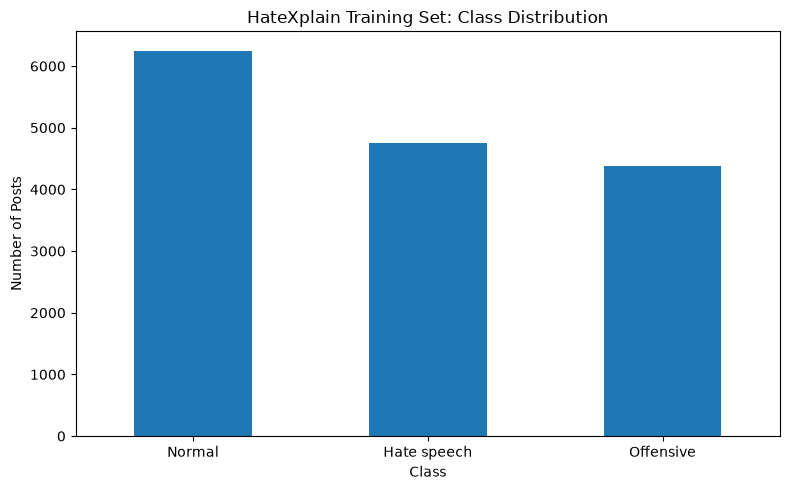

In [11]:
import matplotlib.pyplot as plt

label_counts = train_df["label_name"].value_counts()

plt.figure(figsize=(8, 5))
label_counts.plot(kind="bar")
plt.title("HateXplain Training Set: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
distribution = train_df["label_name"].value_counts().to_frame("Posts")
distribution["Percentage"] = (
    distribution["Posts"] / len(train_df) * 100
).round(2)

distribution

,Posts,Percentage
label_name,,
Normal,6251,40.64
Hate speech,4748,30.87
Offensive,4384,28.50


In [13]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(output_dir / "hatexplain_train.csv", index=False)
val_df.to_csv(output_dir / "hatexplain_validation.csv", index=False)
test_df.to_csv(output_dir / "hatexplain_test.csv", index=False)

print("Saved processed datasets:")
for file in sorted(output_dir.glob("hatexplain_*.csv")):
    print(f"{file}: {file.stat().st_size / 1024:.1f} KB")

Saved processed datasets:
../data/processed/hatexplain_test.csv: 516.2 KB
../data/processed/hatexplain_train.csv: 4146.5 KB
../data/processed/hatexplain_validation.csv: 515.3 KB
